# Classification d’images en utilisant le dataset FashionMNIST

In [1]:
import tensorflow as tf
from tensorflow.keras.datasets import fashion_mnist
import matplotlib.pyplot as plt
import seaborn as sns

tf.random.set_seed(42)

(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

I0000 00:00:1792493404.621385   19821 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792493404.944153   19821 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792493407.374782   19821 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 2us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step 
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


# Étape 1 – Exploration du jeu de données

In [2]:
print("Dimensions du train set :", X_train.shape)
print("Dimensions du test set :", X_test.shape)

Dimensions du train set : (60000, 28, 28)
Dimensions du test set : (10000, 28, 28)


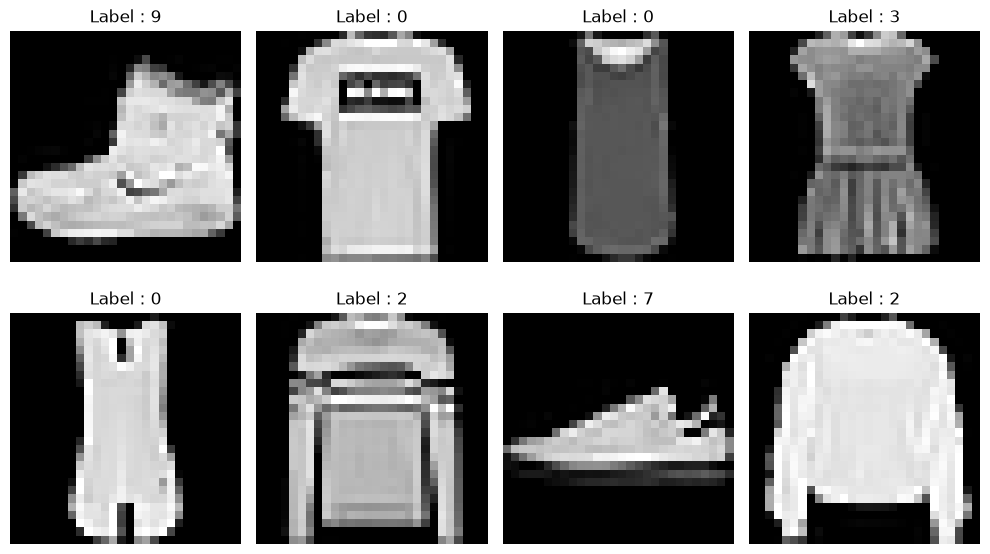

In [10]:
plt.figure(figsize=(10, 6))

for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(X_train[i], cmap='gray')
    plt.title(f"Label : {y_train[i]}")
    plt.axis('off')

plt.tight_layout()
plt.show()

Les données Fashion-MNIST contiennent des images de vêtements en niveaux de gris. Chaque image possède une taille de 28 × 28 pixels et un type uint8. Le jeu d’entraînement contient 60 000 images et le jeu de test contient 10 000 images. Les vêtements sont répartis en 10 classes différentes.

# Étape 2 – Prétraitement des données

In [11]:
from tensorflow.keras.utils import to_categorical

X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

y_train_cat = to_categorical(y_train, 10)
y_test_cat = to_categorical(y_test, 10)

1. La normalisation transforme les valeurs des pixels de l’intervalle [0, 255] vers [0, 1]. Elle facilite et accélère l’apprentissage du modèle.

2. Le one-hot encoding transforme chaque classe en un vecteur de 10 valeurs. La classe correspondante vaut 1 et les autres valent 0. Cela permet au modèle de classifier les images parmi les 10 catégories de Fashion-MNIST.

# Étape 3 – Création d’un modèle dense (ANN)

In [12]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Flatten, Dense, Dropout
import matplotlib.pyplot as plt

model = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.2),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

model.summary()

E0000 00:00:1792494620.916552   19821 cuda_platform.cc:57] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
=== Source Location Trace: === 
external/xla/xla/stream_executor/cuda/cuda_status.cc:50



Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    X_train, y_train_cat,
    epochs=10,
    batch_size=128,
    validation_split=0.2
)

Epoch 1/10


W0000 00:00:1792494652.776721   19821 cpu_allocator_impl.cc:174] Allocation of 150528000 exceeds 10% of free system memory.


369/375 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7757 - loss: 0.6374

W0000 00:00:1792494658.661650   19821 cpu_allocator_impl.cc:174] Allocation of 37632000 exceeds 10% of free system memory.


375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - accuracy: 0.7765 - loss: 0.6356 - val_accuracy: 0.8343 - val_loss: 0.4601
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8465 - loss: 0.4322 - val_accuracy: 0.8591 - val_loss: 0.3964
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.8581 - loss: 0.3899 - val_accuracy: 0.8621 - val_loss: 0.3811
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.8691 - loss: 0.3602 - val_accuracy: 0.8687 - val_loss: 0.3665
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8739 - loss: 0.3443 - val_accuracy: 0.8716 - val_loss: 0.3536
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8792 - loss: 0.3287 - val_accuracy: 0.8733 - val_loss: 0.3522
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.8831 - loss: 0.3182 - val_accuracy: 0.8742 - val_loss: 0.3451
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.8878 - loss: 0.3048 - val_accuracy: 0.8811 -

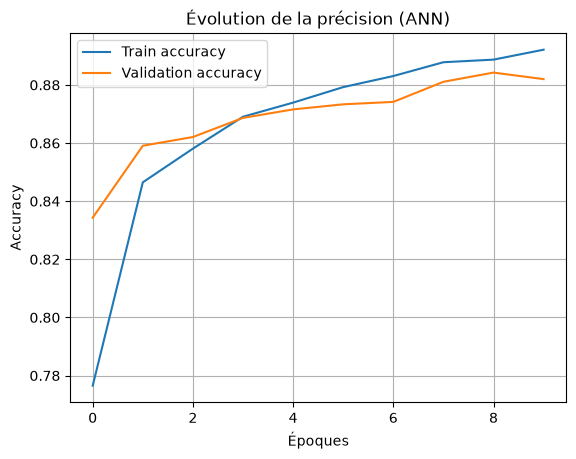

In [14]:
plt.plot(history.history['accuracy'], label='Train accuracy')
plt.plot(history.history['val_accuracy'], label='Validation accuracy')
plt.legend()
plt.title('Évolution de la précision (ANN)')
plt.xlabel('Époques')
plt.ylabel('Accuracy')
plt.grid(True)
plt.show()

1. ReLU transforme les valeurs négatives en 0 et conserve les valeurs positives. Elle permet au réseau de neurones d’apprendre des relations non linéaires et facilite l’entraînement.
2. accuracy : précision du modèle sur les données d’entraînement. val_accuracy : précision du modèle sur les données de validation, non utilisées pour ajuster les poids.
3. Le modèle peut améliorer sa précision en apprenant davantage, mais le temps d’entraînement augmente et le risque de surapprentissage apparaît si les performances sur les données de validation commencent à diminuer.

In [15]:
test_loss, test_acc = model.evaluate(X_test, y_test_cat)
print(f"Précision sur le test est : {test_acc}")

 27/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8819 - loss: 0.3319

W0000 00:00:1792495057.279549   19821 cpu_allocator_impl.cc:174] Allocation of 31360000 exceeds 10% of free system memory.


313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8775 - loss: 0.3520
Précision sur le test est : 0.8774999976158142


# Étape 4 — Introduction aux Fonctions d’Activation

W0000 00:00:1792495367.475528   19821 cpu_allocator_impl.cc:174] Allocation of 150528000 exceeds 10% of free system memory.
W0000 00:00:1792495370.834552   19821 cpu_allocator_impl.cc:174] Allocation of 37632000 exceeds 10% of free system memory.


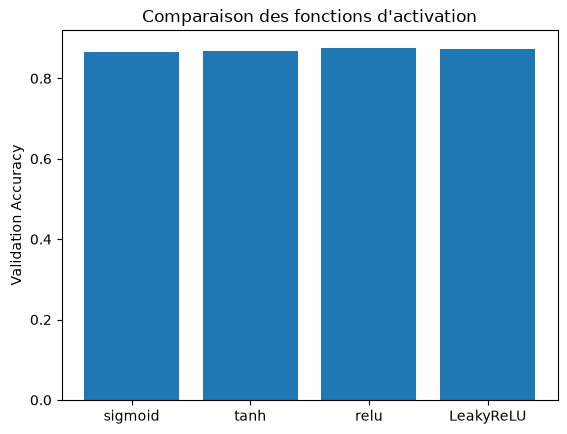

{'sigmoid': 0.8665833473205566, 'tanh': 0.8692499995231628, 'relu': 0.8756666779518127, 'LeakyReLU': 0.872083306312561}


In [16]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Flatten, Dense, LeakyReLU
import matplotlib.pyplot as plt

activations = ['sigmoid', 'tanh', 'relu']
results = {}

for act in activations:
    model_act = Sequential([Input(shape=(28, 28)), Flatten(), Dense(128, activation=act),
                            Dense(64, activation=act), Dense(10, activation='softmax')])

    model_act.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    h = model_act.fit(X_train, y_train_cat, epochs=5, batch_size=128, validation_split=0.2, verbose=0)
    results[act] = h.history['val_accuracy'][-1]

model_leaky = Sequential([Input(shape=(28, 28)), Flatten(), Dense(128), LeakyReLU(negative_slope=0.1),
                          Dense(64), LeakyReLU(negative_slope=0.1), Dense(10, activation='softmax')])

model_leaky.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
h = model_leaky.fit(X_train, y_train_cat, epochs=5, batch_size=128, validation_split=0.2, verbose=0)

results['LeakyReLU'] = h.history['val_accuracy'][-1]

plt.bar(results.keys(), results.values())
plt.title("Comparaison des fonctions d'activation")
plt.ylabel("Validation Accuracy")
plt.show()

print(results)

1. ReLU donne les meilleurs résultats avec une précision de validation de 87,57 %.
2. Elles peuvent provoquer le problème du gradient qui disparaît (vanishing gradient), ce qui ralentit l’apprentissage du réseau.
3. LeakyReLU conserve une petite valeur négative pour les entrées négatives, contrairement à ReLU qui renvoie zéro. Cela permet de limiter le problème des neurones qui cessent d’apprendre.

# Étape 5 : Modèle CNN (Convolutional Neural Network)

In [17]:
from tensorflow.keras.layers import Conv2D, MaxPooling2D

X_train_cnn = X_train.reshape(-1, 28, 28, 1)
X_test_cnn = X_test.reshape(-1, 28, 28, 1)

cnn = Sequential([
    Input(shape=(28, 28, 1)),
    Conv2D(32, (3,3), activation='relu'),
    MaxPooling2D((2,2)),
    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D((2,2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(10, activation='softmax')
])
cnn.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
cnn.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [18]:
history_cnn = cnn.fit(
    X_train_cnn, y_train_cat,
    epochs=10,
    batch_size=128,
    validation_split=0.2
)

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 38s 97ms/step - accuracy: 0.7702 - loss: 0.6345 - val_accuracy: 0.8528 - val_loss: 0.4086
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 32s 85ms/step - accuracy: 0.8569 - loss: 0.3988 - val_accuracy: 0.8750 - val_loss: 0.3430
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 31s 82ms/step - accuracy: 0.8750 - loss: 0.3457 - val_accuracy: 0.8852 - val_loss: 0.3142
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 32s 84ms/step - accuracy: 0.8853 - loss: 0.3143 - val_accuracy: 0.8899 - val_loss: 0.2966
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 30s 80ms/step - accuracy: 0.8933 - loss: 0.2908 - val_accuracy: 0.8921 - val_loss: 0.2915
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 32s 84ms/step - accuracy: 0.9004 - loss: 0.2716 - val_accuracy: 0.8982 - val_loss: 0.2806
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 31s 83ms/step - accuracy: 0.9045 - loss: 0.2581 - val_accuracy: 0.9019 - val_loss: 0.2673
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 31s 82ms/step - accuracy: 0.9115 - loss: 0.2419 - 

In [19]:
test_loss, test_acc = cnn.evaluate(X_test_cnn, y_test_cat)
print("Précision CNN sur test set :", test_acc)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9041 - loss: 0.2671
Précision CNN sur test set : 0.9041000008583069


1. ANN (Réseau classique) : Il "aplatit" l'image en une simple liste de nombres. Il ne comprend pas la position des pixels.
CNN (Réseau Convolutif) : Il analyse l'image par petits morceaux (filtres) pour comprendre les formes (bords, contours) et garde la structure spatiale de l'image.

2. Parce qu'il est spécialement conçu pour les images. Il est capable de reconnaître un objet même s'il est décalé ou légèrement modifié sur l'image, et il utilise beaucoup moins de paramètres qu'un ANN, ce qui évite qu'il n'apprenne "par cœur".

3. Réduire la taille des données (images) pour rendre les calculs plus rapides.
Garder l'essentiel (les caractéristiques les plus importantes) tout en supprimant les détails inutiles, ce qui aide le modèle à être plus robuste.

# Étape 6 — Visualisation des performances

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step


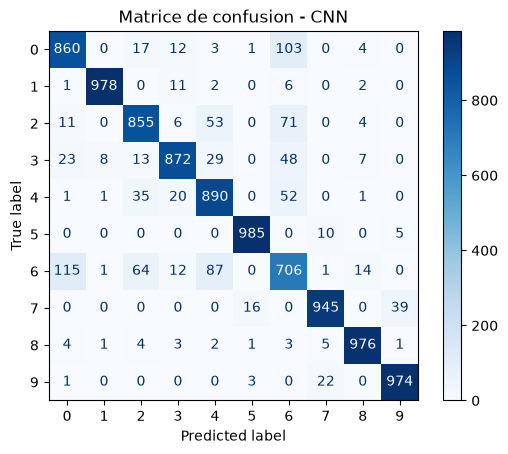

In [20]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import numpy as np

y_pred = np.argmax(cnn.predict(X_test_cnn), axis=1)
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues")
plt.title("Matrice de confusion - CNN")
plt.show()

1. En observant les valeurs les plus élevées en dehors de la diagonale (qui représente les bonnes prédictions), on remarque que le chiffre 6 est le plus problématique.

2.Puisque ces erreurs concernent des chiffres avec des boucles ou des formes similaires lorsqu'ils sont mal écrits, voici les solutions :

La Data Augmentation  : Appliquer de légères rotations ou des translations (décalages) permettra au modèle de mieux généraliser.

Améliorer le prétraitement : S'assurer que les chiffres sont bien centrés et normalisés.

Complexifier le modèle : Ajouter une couche de convolution supplémentaire ou ajuster les paramètres pour que le réseau apprenne des détails plus fins (comme la petite boucle en bas du 6 par rapport au 0).

# Étape 7 : Data Augmentation

In [21]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

datagen = ImageDataGenerator(
    rotation_range=10,
    zoom_range=0.1,
    horizontal_flip=True
)

datagen.fit(X_train_cnn)

cnn.fit(
    datagen.flow(X_train_cnn, y_train_cat, batch_size=128),
    epochs=10,
    validation_data=(X_test_cnn, y_test_cat)
)

Epoch 1/10


I0000 00:00:1792496874.032731   19821 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.


469/469 ━━━━━━━━━━━━━━━━━━━━ 77s 161ms/step - accuracy: 0.8622 - loss: 0.3850 - val_accuracy: 0.9008 - val_loss: 0.2789
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 74s 157ms/step - accuracy: 0.8803 - loss: 0.3291 - val_accuracy: 0.9018 - val_loss: 0.2732
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 67s 142ms/step - accuracy: 0.8866 - loss: 0.3103 - val_accuracy: 0.9090 - val_loss: 0.2617
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 72s 154ms/step - accuracy: 0.8902 - loss: 0.2982 - val_accuracy: 0.9035 - val_loss: 0.2650
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 45s 96ms/step - accuracy: 0.8927 - loss: 0.2905 - val_accuracy: 0.9071 - val_loss: 0.2605
Epoch 6/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 84s 100ms/step - accuracy: 0.8968 - loss: 0.2807 - val_accuracy: 0.9057 - val_loss: 0.2530
Epoch 7/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 80s 97ms/step - accuracy: 0.8985 - loss: 0.2757 - val_accuracy: 0.9084 - val_loss: 0.2545
Epoch 8/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 46s 99ms/step - accuracy: 0.9003 - loss: 0.2679 - val_ac

1. Cela permet d'augmenter artificiellement le nombre d'images d'entraînement en créant des copies modifiées (tournées, zoomées...). Cela évite que le modèle n'apprenne "par cœur" (sur-apprentissage) et le rend plus robuste.

2. Pour des chiffres (MNIST), la rotation et le zoom sont très efficaces. En revanche, le horizontal_flip=True (effet miroir) n'est pas du tout efficace ici : un "3" ou un "2" inversé en miroir ne correspond plus à la classe d'origine. Il vaudrait mieux le désactiver (False) pour ce cas précis.

